<a href="https://colab.research.google.com/github/DDDBBBPPP/visualizacion-datos/blob/main/visualizacion_dbp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Visualización de datos con Matplotlib y Seaborn

El objetivo es representar distintos conjuntos de datos, elegir el gráfico más adecuado para cada situación y comparar la facilidad de implementación y personalización de ambas bibliotecas.

**Gráficos seleccionados:** barras agrupadas, líneas, histograma, dispersión y burbujas.



## 1. Importación de bibliotecas

Utilizaremos **Pandas** para trabajar con los datos, **Matplotlib** para crear gráficos y **Seaborn** para generar visualizaciones estadísticas de forma más sencilla.


In [17]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



## 2. Gráfico 1 — Barras agrupadas

**Objetivo:** comparar las ventas de distintos géneros de videojuegos entre varias plataformas.

**Datos:** simulados, expresados en millones de unidades vendidas.

Este gráfico permite comparar tanto los géneros dentro de una plataforma como las diferencias entre plataformas para un mismo género.


In [18]:

df_videojuegos = pd.DataFrame({
    'Genero': ['Acción', 'Aventura', 'RPG', 'Deportes', 'Estrategia'],
    'PC': [42, 35, 58, 18, 46],
    'PlayStation': [75, 62, 55, 68, 20],
    'Xbox': [60, 45, 38, 52, 15]
})

display(df_videojuegos)


,Genero,PC,PlayStation,Xbox
0,Acción,42,75,60
1,Aventura,35,62,45
2,RPG,58,55,38
3,Deportes,18,68,52
4,Estrategia,46,20,15



### 2.1. Visualización con Matplotlib

Con Matplotlib construimos manualmente los grupos de barras, calculando sus posiciones y desplazamientos para representar las tres plataformas.


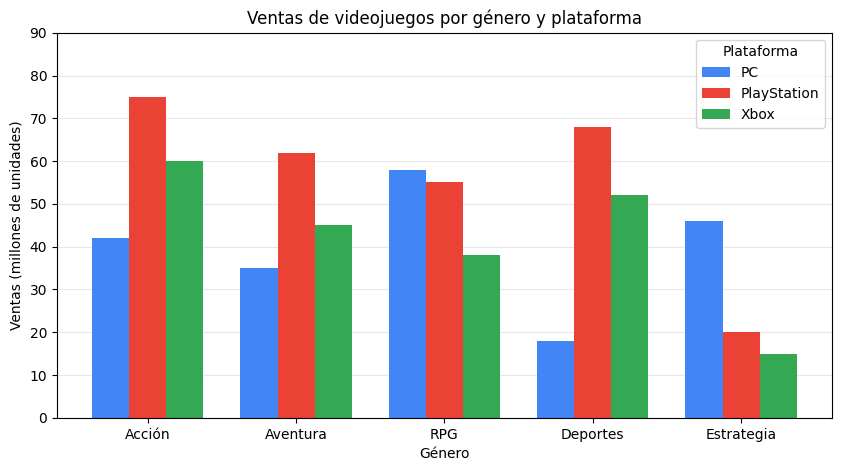

In [19]:

x = np.arange(len(df_videojuegos))
ancho = 0.25

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(x - ancho, df_videojuegos['PC'], ancho, label='PC', color='#4285F4')
ax.bar(x, df_videojuegos['PlayStation'], ancho, label='PlayStation', color='#EA4335')
ax.bar(x + ancho, df_videojuegos['Xbox'], ancho, label='Xbox', color='#34A853')

ax.set_title('Ventas de videojuegos por género y plataforma')
ax.set_xlabel('Género')
ax.set_ylabel('Ventas (millones de unidades)')
ax.set_xticks(x)
ax.set_xticklabels(df_videojuegos['Genero'])
ax.set_ylim(0, 90)
ax.legend(title='Plataforma')
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)

plt.show()



### 2.2. Visualización con Seaborn

Seaborn permite agrupar automáticamente las barras mediante el parámetro `hue`, evitando calcular manualmente las posiciones de cada plataforma.

Para ello, primero adaptamos el DataFrame al formato largo.


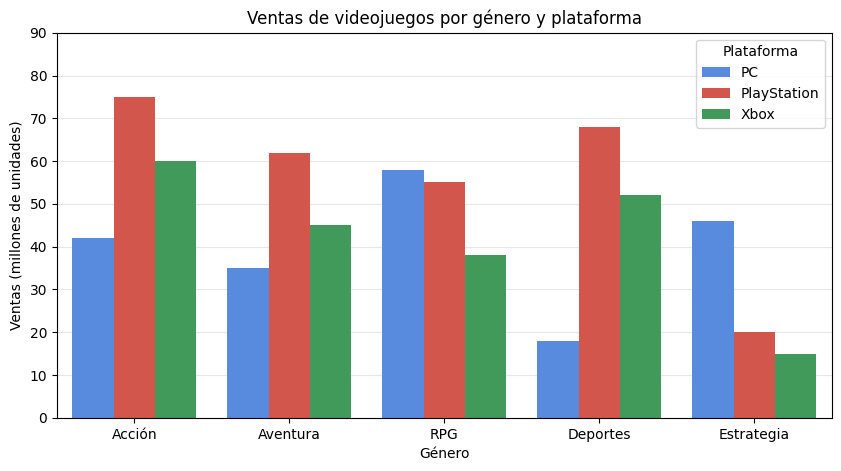

In [20]:

# Convertimos las columnas de plataformas en una sola variable
df_videojuegos_largo = df_videojuegos.melt(
    id_vars='Genero',
    var_name='Plataforma',
    value_name='Ventas'
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=df_videojuegos_largo,
    x='Genero',
    y='Ventas',
    hue='Plataforma',
    palette=['#4285F4', '#EA4335', '#34A853']
)

ax.set_title('Ventas de videojuegos por género y plataforma')
ax.set_xlabel('Género')
ax.set_ylabel('Ventas (millones de unidades)')
ax.set_ylim(0, 90)
ax.legend(title='Plataforma')
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)

plt.show()



### 2.3. Comparación

Ambas bibliotecas representan la misma información y producen resultados visualmente similares.

- **Matplotlib:** requiere calcular las posiciones de las barras y dibujar cada plataforma por separado.
- **Seaborn:** agrupa las barras automáticamente mediante `hue`, aunque necesita los datos en formato largo.

**Conclusión:** para este ejemplo, Seaborn simplifica la creación de barras agrupadas, especialmente cuando existen varias categorías.



## 3. Gráfico 2 — Líneas

**Objetivo:** comparar la evolución de las temperaturas máximas y mínimas de Madrid durante enero de 1921.

**Tipo de análisis:** evolución temporal (*Line Chart* del Chart Chooser).

**Datos:** registros meteorológicos históricos de estaciones españolas, procedentes de un conjunto de datos de AEMET.

El gráfico de líneas permite observar las variaciones de temperatura a lo largo del mes y comparar ambas series.


In [21]:

url = "https://raw.githubusercontent.com/DDDBBBPPP/visualizacion-datos/main/datos/1921.CSV"

df_temperaturas = pd.read_csv(url)

# Seleccionamos Madrid y enero de 1921
df_madrid = df_temperaturas[
    (df_temperaturas['station_name'] == 'MADRID') &
    (df_temperaturas['date'].str.startswith('1921-01'))
].copy()

df_madrid['date'] = pd.to_datetime(df_madrid['date'])

display(df_madrid[['date', 'temperature_max[C]', 'temperature_min[C]']].head())


,date,temperature_max[C],temperature_min[C]
5,1921-01-01,11.2,0.2
15,1921-01-02,9.8,3.8
25,1921-01-03,4.7,2.5
35,1921-01-04,5.8,1.7
45,1921-01-05,9.3,3.4



### 3.1. Visualización con Matplotlib

Con Matplotlib representamos manualmente las dos series de temperaturas, configurando cada línea por separado.

El eje horizontal muestra los días de enero y el vertical las temperaturas en grados Celsius.

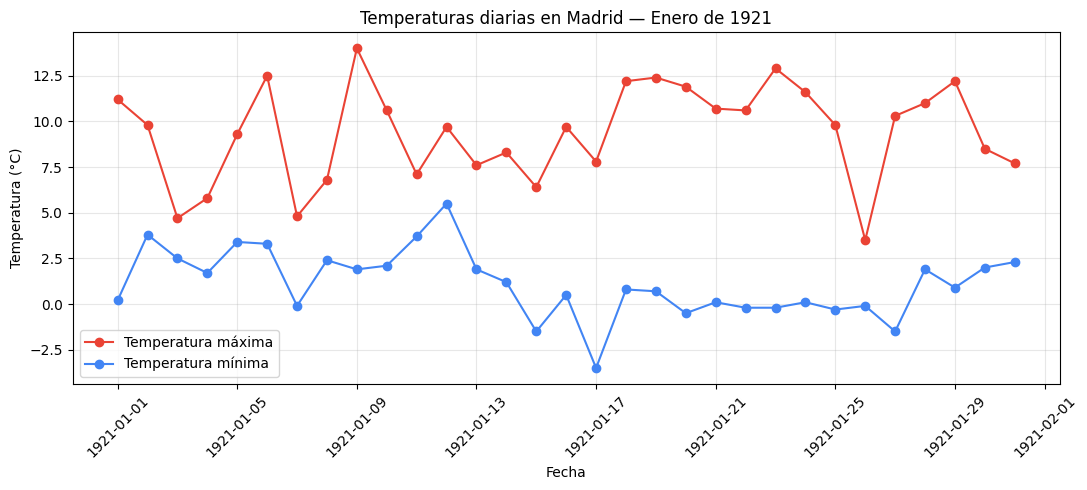

In [22]:

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    df_madrid['date'],
    df_madrid['temperature_max[C]'],
    color='#EA4335',
    marker='o',
    label='Temperatura máxima'
)

ax.plot(
    df_madrid['date'],
    df_madrid['temperature_min[C]'],
    color='#4285F4',
    marker='o',
    label='Temperatura mínima'
)

ax.set_title('Temperaturas diarias en Madrid — Enero de 1921')
ax.set_xlabel('Fecha')
ax.set_ylabel('Temperatura (°C)')
ax.legend()
ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



### 3.2. Visualización con Seaborn

Seaborn permite representar varias series temporales de forma automática mediante `hue`, que diferencia cada estación meteorológica por colores y genera su leyenda.

En este ejemplo comparamos las temperaturas máximas diarias de varias estaciones españolas durante enero de 1921, sin necesidad de dibujar cada línea individualmente.



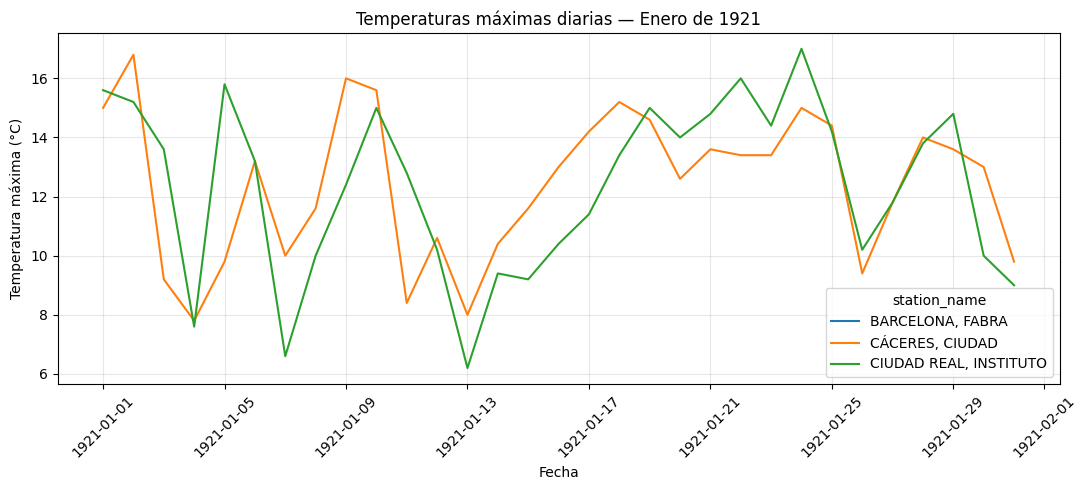

In [23]:

# Seleccionamos enero de 1921 y tres estaciones
df_enero = df_temperaturas[
    df_temperaturas['date'].str.startswith('1921-01')
].copy()

estaciones = df_enero['station_name'].dropna().unique()[:3]
df_enero = df_enero[df_enero['station_name'].isin(estaciones)]

df_enero['date'] = pd.to_datetime(df_enero['date'])

plt.figure(figsize=(11, 5))

sns.lineplot(
    data=df_enero,
    x='date',
    y='temperature_max[C]',
    hue='station_name'
)

plt.title('Temperaturas máximas diarias — Enero de 1921')
plt.xlabel('Fecha')
plt.ylabel('Temperatura máxima (°C)')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### 3.3. Comparación

- **Matplotlib:** permite configurar individualmente cada línea y ofrece un control detallado sobre la representación.
- **Seaborn:** facilita la comparación de múltiples estaciones mediante `hue`, automatizando la agrupación, los colores y la leyenda.

**Conclusión:** Matplotlib resulta sencillo para representar pocas series, mientras que Seaborn destaca cuando necesitamos comparar varias categorías dentro de un mismo gráfico.




## 4. Gráfico 3 — Histograma

**Objetivo:** analizar cómo se distribuyen las calificaciones de un grupo de estudiantes.

**Tipo de análisis:** distribución de una variable (*Column Histogram* del Chart Chooser).

**Datos:** 200 calificaciones simuladas entre 0 y 10.

El histograma permite identificar dónde se concentran las notas, su dispersión y la forma de la distribución.


In [24]:

# Generamos 200 calificaciones ficticias
np.random.seed(42)

notas = np.random.normal(loc=6, scale=1.8, size=200)
notas = np.clip(notas, 0, 10)

df_notas = pd.DataFrame({'Nota': notas.round(2)})

display(df_notas.head())


,Nota
0,6.89
1,5.75
2,7.17
3,8.74
4,5.58



### 4.1. Visualización con Matplotlib

Con Matplotlib construimos el histograma indicando manualmente los intervalos de notas y su apariencia.

Cada barra muestra cuántos estudiantes han obtenido una calificación dentro de un intervalo.


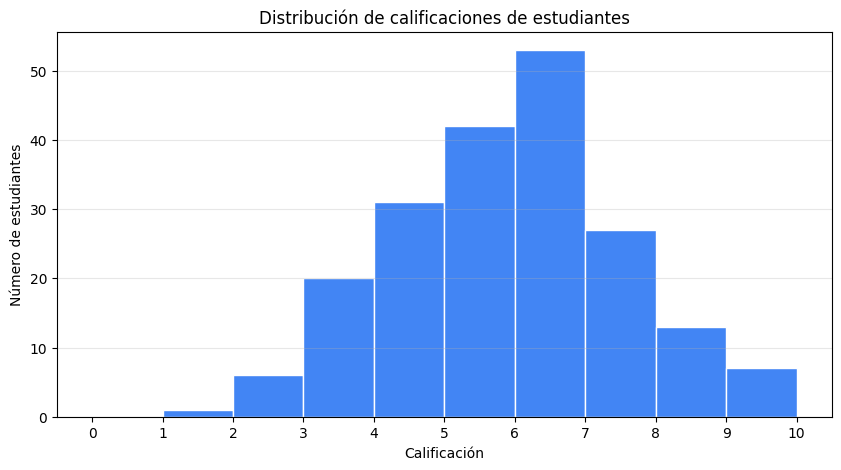

In [25]:

plt.figure(figsize=(10, 5))

plt.hist(
    df_notas['Nota'],
    bins=np.arange(0, 11, 1),
    color='#4285F4',
    edgecolor='white'
)

plt.title('Distribución de calificaciones de estudiantes')
plt.xlabel('Calificación')
plt.ylabel('Número de estudiantes')
plt.xticks(range(11))
plt.grid(axis='y', alpha=0.3)

plt.show()



### 4.2. Visualización con Seaborn

Seaborn permite representar la distribución de las calificaciones y añadir una curva de densidad mediante `kde=True`.

Esta curva ayuda a visualizar la forma general de la distribución sin depender únicamente de las barras del histograma.


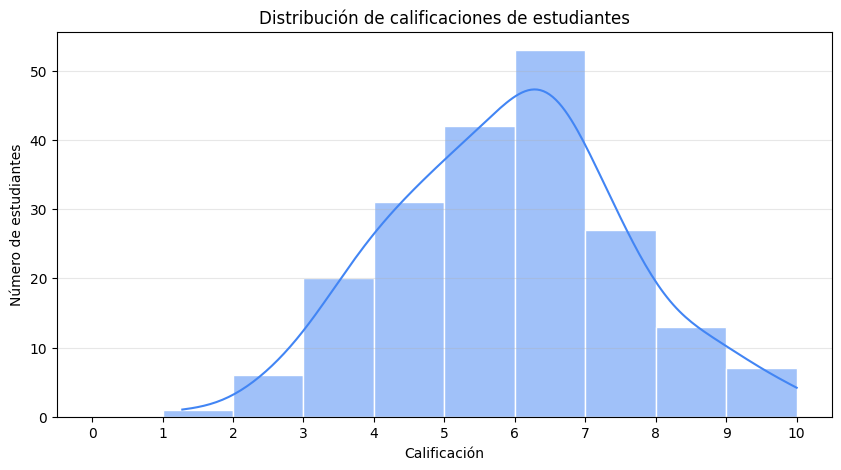

In [26]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_notas,
    x='Nota',
    bins=np.arange(0, 11, 1),
    kde=True,
    color='#4285F4',
    edgecolor='white'
)

plt.title('Distribución de calificaciones de estudiantes')
plt.xlabel('Calificación')
plt.ylabel('Número de estudiantes')
plt.xticks(range(11))
plt.grid(axis='y', alpha=0.3)

plt.show()



### 4.3. Comparación

- **Matplotlib:** permite crear y personalizar el histograma, controlando los intervalos y la frecuencia de las observaciones.
- **Seaborn:** ofrece una representación equivalente y permite incorporar fácilmente una curva de densidad con `kde=True`.

**Conclusión:** Seaborn facilita el análisis estadístico de distribuciones al incorporar funcionalidades adicionales sin necesidad de calcular y dibujar manualmente la curva de densidad.



## 5. Gráfico 4 — Dispersión

**Objetivo:** analizar la relación entre la longitud y la anchura de los pétalos de distintas especies de flores Iris.

**Tipo de análisis:** relación entre dos variables (*Scatter Chart* del Chart Chooser).

**Datos:** dataset real Iris, incluido en Scikit-learn. Contiene 150 flores de tres especies y cuatro medidas en centímetros.

El gráfico de dispersión permite observar correlaciones, agrupaciones y diferencias entre especies.


In [32]:

from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)

df_iris = iris.frame.copy()

# Sustituimos los códigos numéricos por los nombres de las especies
df_iris['Especie'] = df_iris['target'].map(
    dict(enumerate(iris.target_names))
)

display(df_iris.head())


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,Especie
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa



### 5.1. Visualización con Matplotlib

Con Matplotlib agrupamos los datos por especie y dibujamos cada grupo por separado para asignarle un color y una etiqueta.

Esto permite identificar visualmente si las especies presentan diferencias en las medidas de sus pétalos.


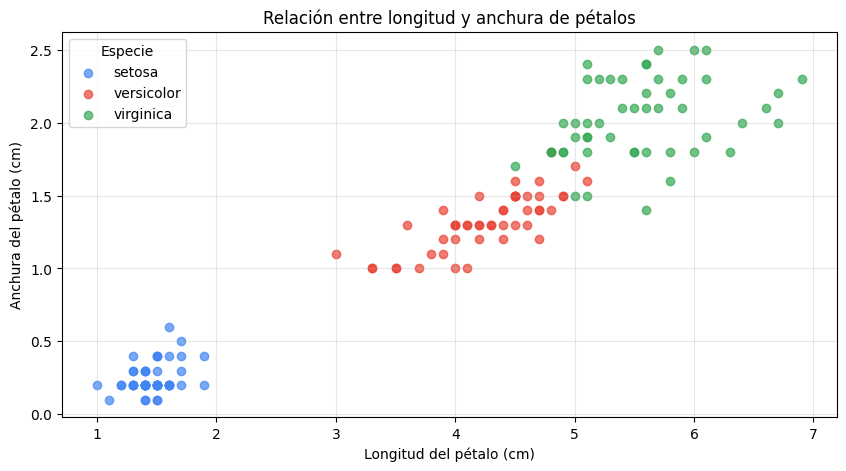

In [33]:

colores = {
    'setosa': '#4285F4',
    'versicolor': '#EA4335',
    'virginica': '#34A853'
}

plt.figure(figsize=(10, 5))

for especie, grupo in df_iris.groupby('Especie'):
    plt.scatter(
        grupo['petal length (cm)'],
        grupo['petal width (cm)'],
        label=especie,
        color=colores[especie],
        alpha=0.7
    )

plt.title('Relación entre longitud y anchura de pétalos')
plt.xlabel('Longitud del pétalo (cm)')
plt.ylabel('Anchura del pétalo (cm)')
plt.legend(title='Especie')
plt.grid(alpha=0.3)

plt.show()



### 5.2. Visualización con Seaborn

Seaborn permite representar las tres especies mediante una única llamada a `sns.scatterplot()`.

El parámetro `hue` asigna automáticamente los colores y genera la leyenda, sin necesidad de recorrer manualmente cada especie.


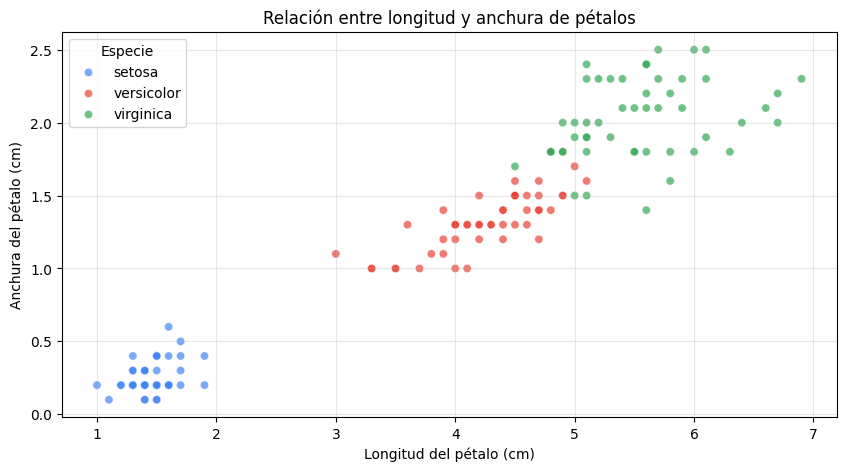

In [31]:

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df_iris,
    x='petal length (cm)',
    y='petal width (cm)',
    hue='Especie',
    palette=colores,
    alpha=0.7
)

plt.title('Relación entre longitud y anchura de pétalos')
plt.xlabel('Longitud del pétalo (cm)')
plt.ylabel('Anchura del pétalo (cm)')
plt.legend(title='Especie')
plt.grid(alpha=0.3)

plt.show()



### 5.3. Comparación

- **Matplotlib:** requiere agrupar las observaciones por especie y utilizar un bucle para representar cada grupo.
- **Seaborn:** utiliza `hue` para diferenciar automáticamente las especies mediante colores y generar la leyenda.

**Conclusión:** Seaborn simplifica las visualizaciones con múltiples categorías y facilita la identificación de patrones y agrupaciones en los datos.



## 6. Gráfico 5 — Burbujas

**Objetivo:** analizar la relación entre la potencia y la eficiencia de combustible de los automóviles, teniendo en cuenta también su peso y origen.

**Tipo de análisis:** relación entre tres variables (*Bubble Chart* del Chart Chooser).

**Datos:** dataset real Auto MPG, disponible en Seaborn, con información sobre automóviles de distintas procedencias.

Cada burbuja representa un vehículo:
- **Eje X:** potencia del motor.
- **Eje Y:** eficiencia de combustible (millas por galón, MPG).
- **Tamaño:** peso del automóvil.
- **Color:** región de origen.

El gráfico permite observar varias características de los vehículos simultáneamente.


In [34]:
# Cargamos el dataset Auto MPG
df_coches = sns.load_dataset('mpg')

# Eliminamos registros sin las variables necesarias
df_coches = df_coches.dropna(
    subset=['horsepower', 'mpg', 'weight', 'origin']
)

display(df_coches.head())


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino



### 6.1. Visualización con Matplotlib

Con Matplotlib debemos transformar el peso de los vehículos en tamaños de burbuja y agrupar los datos por región de origen para asignar los colores.

El tamaño de cada punto representa el peso relativo del automóvil.


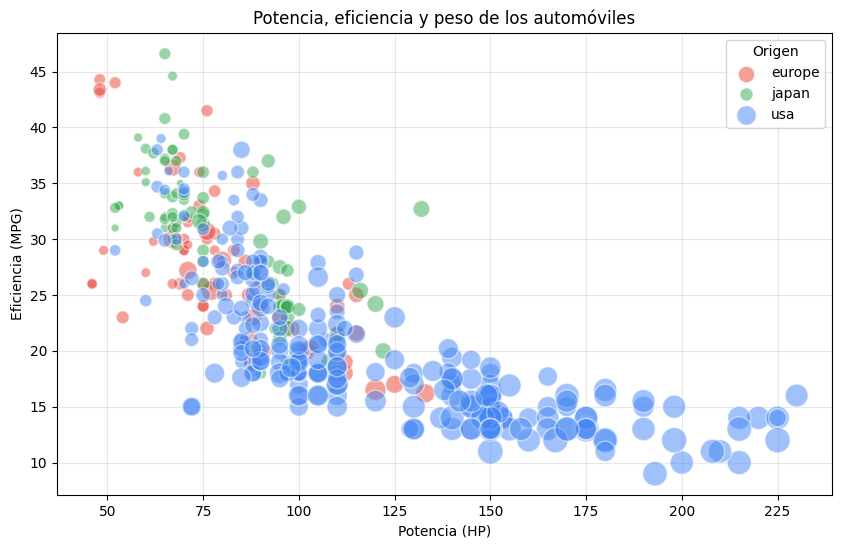

In [35]:

colores_coches = {
    'usa': '#4285F4',
    'europe': '#EA4335',
    'japan': '#34A853'
}

# Normalizamos los tamaños para que las burbujas sean legibles
tam_min, tam_max = 30, 350

tamanos = tam_min + (
    (df_coches['weight'] - df_coches['weight'].min()) /
    (df_coches['weight'].max() - df_coches['weight'].min())
) * (tam_max - tam_min)

fig, ax = plt.subplots(figsize=(10, 6))

for origen, grupo in df_coches.groupby('origin'):
    ax.scatter(
        grupo['horsepower'],
        grupo['mpg'],
        s=tamanos.loc[grupo.index],
        color=colores_coches[origen],
        alpha=0.5,
        edgecolors='white',
        label=origen
    )

ax.set_title('Potencia, eficiencia y peso de los automóviles')
ax.set_xlabel('Potencia (HP)')
ax.set_ylabel('Eficiencia (MPG)')
ax.legend(title='Origen')
ax.grid(alpha=0.3)
ax.set_axisbelow(True)

plt.show()



### 6.2. Visualización con Seaborn

Seaborn permite representar varias variables simultáneamente mediante una única función.

- `hue` asigna colores según la región de origen.
- `size` modifica el tamaño de las burbujas según el peso.
- `sizes` establece el intervalo de tamaños.

Además, Seaborn genera automáticamente una leyenda que identifica tanto los colores como los tamaños.


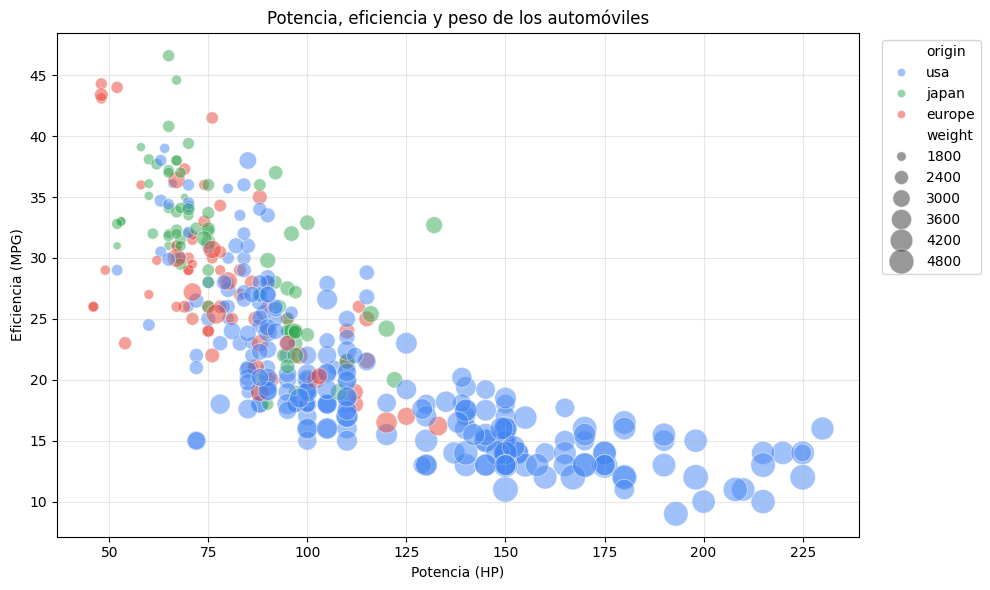

In [36]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_coches,
    x='horsepower',
    y='mpg',
    hue='origin',
    size='weight',
    sizes=(30, 350),
    palette=colores_coches,
    alpha=0.5,
    edgecolor='white'
)

plt.title('Potencia, eficiencia y peso de los automóviles')
plt.xlabel('Potencia (HP)')
plt.ylabel('Eficiencia (MPG)')
plt.grid(alpha=0.3)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()

plt.show()



### 6.3. Comparación

- **Matplotlib:** requiere normalizar manualmente los tamaños de las burbujas, agrupar los vehículos por origen y configurar los colores.
- **Seaborn:** permite representar las mismas variables mediante `hue` y `size`, automatizando los tamaños, colores y leyendas.

**Conclusión:** Seaborn simplifica considerablemente las visualizaciones multivariantes, especialmente cuando queremos representar varias características de los datos en un mismo gráfico.



## 7. Conclusiones

**Matplotlib** ofrece un control detallado sobre los elementos de cada gráfico, aunque algunas visualizaciones requieren más configuración manual.

**Seaborn**, construido sobre Matplotlib, facilita especialmente las representaciones estadísticas y multivariantes mediante parámetros como `hue`, `size` y `kde`.

No obstante, Seaborn no siempre necesita menos código: su ventaja depende del tipo de gráfico y de la estructura de los datos.

